# Музыкальные рекомендации на Yambda: сравнение пяти моделей

**Задача:** для каждого пользователя построить персональный top-10 **новых** треков, то есть тех, что он ещё не слушал, на следующую неделю.

Как запустить: `pip install -r requirements.txt`, выполнить `prepare_data.ipynb` (подвыборка ляжет в `data/yambda_subsample/`),
  потом запустить этот ноутбук из папки `hw1/`.

Seed, размеры окон и K задаются в ячейке ниже.

In [ ]:
import os
import shutil
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

SEED = 42
K = 10
VAL_DAYS = 7
TEST_DAYS = 7
MAIN_METRIC = f"ndcg@{K}"

np.random.seed(SEED)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import files

    if not os.path.exists("/content/yambda/models/common.py"):
        import subprocess
        import zipfile

        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "polars"], check=True)
        uploaded = files.upload()  # yambda_bundle.zip
        with zipfile.ZipFile(next(iter(uploaded))) as z:
            z.extractall("/content/yambda")
    os.chdir("/content/yambda")


from models.common import DAY, LISTEN_PLUS, load_subsample, make_splits, recommend
from models.metrics import evaluate
from models.popular import Popular
from models.ease import EASE
from models.itemknn import ItemKNN
from models.ials import IALS
from models.ials_custom import IALSCustom
from models.fm import FM, item_metadata
from models.tuning import run, tune

import optuna
import torch

optuna.logging.set_verbosity(optuna.logging.WARNING)
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

DATA_DIR = "data/yambda_subsample"
data = load_subsample(DATA_DIR)
meta = data["meta"]
print(DATA_DIR, "| FM:", "cuda " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
meta

data/yambda_subsample | FM: cpu


/private/tmp/claude-501/-Users-higz-mipt-recsys/50821e92-49a5-4b94-aea0-4ebc3a95e4af/scratchpad/venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'source': 'https://huggingface.co/datasets/yandex/yambda (flat/50m)',
 'seed': 42,
 'params': {'n_days': 60,
  'user_frac': 0.25,
  'min_item_users': 20,
  'min_user_items': 10},
 't_from': 20816000,
 't_max': 26000000,
 'stats': {'users': 2165,
  'items': 13149,
  'pairs': 736773,
  'listen_events': 1772005,
  'density_%': 2.588,
  'median_items_per_user': 265}}

## 1. Данные

**Yambda** -- открытый датасет Яндекс Музыки ([Hugging Face](https://huggingface.co/datasets/yandex/yambda),
[arXiv:2505.22238](https://arxiv.org/abs/2505.22238), Apache 2.0). Берём версию `flat/50m`: 10 000 пользователей,
около 300 дней логов. Загрузка и отбор подвыборки сделаны в `prepare_data.ipynb`.

| Файл | Поля | Смысл |
|---|---|---|
| `listens` | `uid`, `item_id`, `timestamp`, `is_organic`, `played_ratio_pct`, `track_length_seconds` | прослушивание трека; доля дослушивания (>100% — перемотки назад) |
| `likes` / `unlikes` | `uid`, `item_id`, `timestamp`, `is_organic` | лайк и его отмена |
| `dislikes` / `undislikes` | `uid`, `item_id`, `timestamp`, `is_organic` | дизлайк и его отмена |
| `artist_item_mapping` / `album_item_mapping` | `item_id`, `artist_id` / `album_id` | метаданные трека |

- `timestamp` -- секунды от начала лога, округлённые до 5 с (абсолютные даты скрыты).
- `is_organic = 1` -- прослушивание запустил сам пользователь (поиск, своя коллекция, плейлист, страница артиста или альбома; в том числе повторы), `0` -- трек поставил рекомендатель (персональная лента «Моя волна», рекомендательные подборки).
- Названий треков и артистов нет: все идентификаторы анонимизированы.

**Что рекомендуем:** top-10 треков, которых пользователь не слушал в обучающем периоде.

**Взаимодействие** -- пара (пользователь, трек) с агрегатами по всем событиям пары в периоде: число прослушиваний,
число прослушиваний > 50%, доля дослушивания, доля органики, лайк / дизлайк.

**Релевантный объект на val / test** -- новый для пользователя трек, который он в периоде оценки дослушал больше чем
на 50% (порог Listen+ авторов датасета) или лайкнул, и при этом не дизлайкнул.

In [ ]:
raw = pd.read_csv(os.path.join(DATA_DIR, "raw_overview.csv"))
listens = data["listens"]
volume = pd.DataFrame([
    {"набор": "сырые flat/50m, прослушивания", "события": int(raw.loc[raw.file == "listens", "rows"].iloc[0]),
     "пользователи": int(raw.loc[raw.file == "listens", "users"].iloc[0]),
     "треки": int(raw.loc[raw.file == "listens", "items"].iloc[0])},
    {"набор": "подвыборка, прослушивания", "события": listens.height,
     "пользователи": listens["uid"].n_unique(), "треки": listens["item_id"].n_unique()},
    {"набор": "подвыборка, пары (взаимодействия)", "события": meta["stats"]["pairs"],
     "пользователи": meta["stats"]["users"], "треки": meta["stats"]["items"]},
])
volume

,набор,события,пользователи,треки
0,"сырые flat/50m, прослушивания",46467212,9238,877168
1,"подвыборка, прослушивания",1772005,2165,13149
2,"подвыборка, пары (взаимодействия)",736773,2165,13149


**Как получена подвыборка.** Полный `flat/50m` слишком большой для задания: в нём 46 млн прослушиваний, а лимит --
2 млн взаимодействий. Поэтому `prepare_data.ipynb` урезает его в четыре шага:

1. Удаляет дубликаты событий.
2. Оставляет только последние 60 дней лога (`n_days`).
3. Случайно выбирает четверть пользователей (`user_frac` = 0.25, seed 42) и отбрасывает все события остальных.
4. Убирает редкие треки и малоактивных пользователей. Трек остаётся, если его слушали хотя бы 20 человек
   (`min_item_users`), пользователь -- если он слушал хотя бы 10 разных треков (`min_user_items`). После удаления
   редких треков у части пользователей треков становится меньше 10, и наоборот, поэтому фильтрация повторяется,
   пока оба условия не выполнятся одновременно.

Параметры приведены в таблице ниже. Другие варианты (окно 30–120 дней, от четверти до всех пользователей,
порог 20–80 слушателей) сравниваются в `prepare_data.ipynb`.

In [ ]:
pd.Series(meta["params"])

n_days            60.00
user_frac          0.25
min_item_users    20.00
min_user_items    10.00
dtype: float64

## 2. EDA

### 2.1. Пропуски и дубликаты

In [ ]:
rows = []
for name in ["listens", "likes", "dislikes", "unlikes", "undislikes"]:
    df = data[name]
    rows.append({
        "файл": name, "строк": df.height,
        "пропусков": int(sum(df.null_count().row(0))),
        "полных дубликатов": df.height - df.unique().height,
        "повторов (uid, item_id, timestamp)": df.height - df.unique(subset=["uid", "item_id", "timestamp"]).height,
    })
pd.DataFrame(rows)

,файл,строк,пропусков,полных дубликатов,"повторов (uid, item_id, timestamp)"
0,listens,1772005,0,0,0
1,likes,28000,0,0,0
2,dislikes,3095,0,0,0
3,unlikes,4550,0,0,0
4,undislikes,324,0,0,0


**Дубликаты.** В сыром `flat/50m` 588'000 записей прослушиваний (около 1,3% из 46,5 млн) повторяют другую запись
с тем же пользователем, треком и временем с точностью до секунды. Одно прослушивание не может начаться дважды
в одну секунду, так что это одно событие, сохранённое несколько раз. 225'000 из них совпадают с оригиналом во всех
полях, у остальных отличается, например, доля дослушивания.

`prepare_data.ipynb` удаляет такие повторы ещё до отбора подвыборки. Из каждой группы он оставляет запись
с максимальной долей дослушивания, поэтому в таблице выше дубликатов нет.

Повторные прослушивания одного трека в разное время дубликатами не считаются. Это полезный сигнал: сколько раз
пользователь включал трек и сколько раз дослушал его больше чем наполовину, хранится в полях `n_listens` и
`n_full` каждой пары.

### 2.2. Активность пользователей и популярность треков

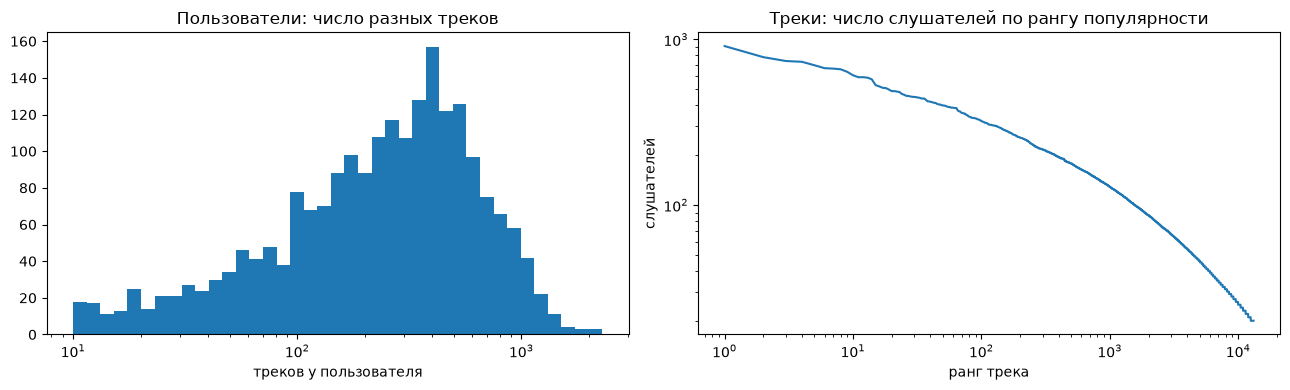

пользователей 2,165, треков 13,149, пар 736,773, разреженность 97.41%
треков у пользователя: медиана 265, 90-й перцентиль 743
слушателей у трека: медиана 36; на 1% самых популярных треков приходится 7.2% пар


In [ ]:
pairs_all = listens.group_by("uid", "item_id").agg(pl.len().alias("n"))
user_act = pairs_all.group_by("uid").len()["len"].to_numpy()
item_pop = pairs_all.group_by("item_id").len()["len"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(user_act, bins=np.logspace(np.log10(user_act.min()), np.log10(user_act.max()), 40))
axes[0].set_xscale("log")
axes[0].set_title("Пользователи: число разных треков")
axes[0].set_xlabel("треков у пользователя")
ranks = np.arange(1, len(item_pop) + 1)
axes[1].loglog(ranks, np.sort(item_pop)[::-1])
axes[1].set_title("Треки: число слушателей по рангу популярности")
axes[1].set_xlabel("ранг трека")
axes[1].set_ylabel("слушателей")
plt.tight_layout()
plt.show()

n_u, n_i = len(user_act), len(item_pop)
top1 = np.sort(item_pop)[::-1][: max(1, n_i // 100)].sum() / item_pop.sum()
print(f"пользователей {n_u:,}, треков {n_i:,}, пар {pairs_all.height:,}, "
      f"разреженность {1 - pairs_all.height / (n_u * n_i):.2%}")
print(f"треков у пользователя: медиана {np.median(user_act):.0f}, 90-й перцентиль {np.percentile(user_act, 90):.0f}")
print(f"слушателей у трека: медиана {np.median(item_pop):.0f}; на 1% самых популярных треков приходится {top1:.1%} пар")

### 2.3. Сигналы: дослушивание, повторы, органика, лайки

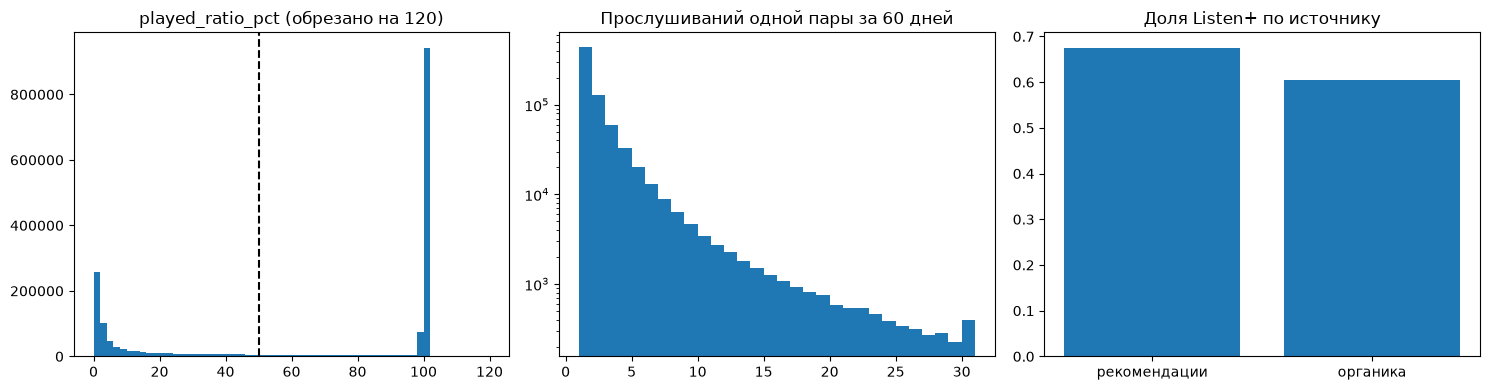

Listen+: 64.0%, органика: 49.3%, пар с повторным прослушиванием: 40.2%
{'likes': 28000, 'unlikes': 4550, 'dislikes': 3095, 'undislikes': 324}


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(listens["played_ratio_pct"].clip(0, 120).to_numpy(), bins=60)
axes[0].axvline(LISTEN_PLUS, color="k", ls="--")
axes[0].set_title("played_ratio_pct (обрезано на 120)")
rep = pairs_all["n"].to_numpy()
axes[1].hist(rep, bins=np.arange(1, 32), log=True)
axes[1].set_title("Прослушиваний одной пары за 60 дней")
by_org = listens.group_by("is_organic").agg((pl.col("played_ratio_pct") > LISTEN_PLUS).mean().alias("listen_plus"))
axes[2].bar(["рекомендации", "органика"], by_org.sort("is_organic")["listen_plus"].to_numpy())
axes[2].set_title("Доля Listen+ по источнику")
plt.tight_layout()
plt.show()

print(f"Listen+: {(listens['played_ratio_pct'] > LISTEN_PLUS).mean():.1%}, "
      f"органика: {listens['is_organic'].mean():.1%}, "
      f"пар с повторным прослушиванием: {(rep > 1).mean():.1%}")
print({k: data[k].height for k in ["likes", "unlikes", "dislikes", "undislikes"]})

### 2.4. Метаданные: артисты, альбомы, длина трека

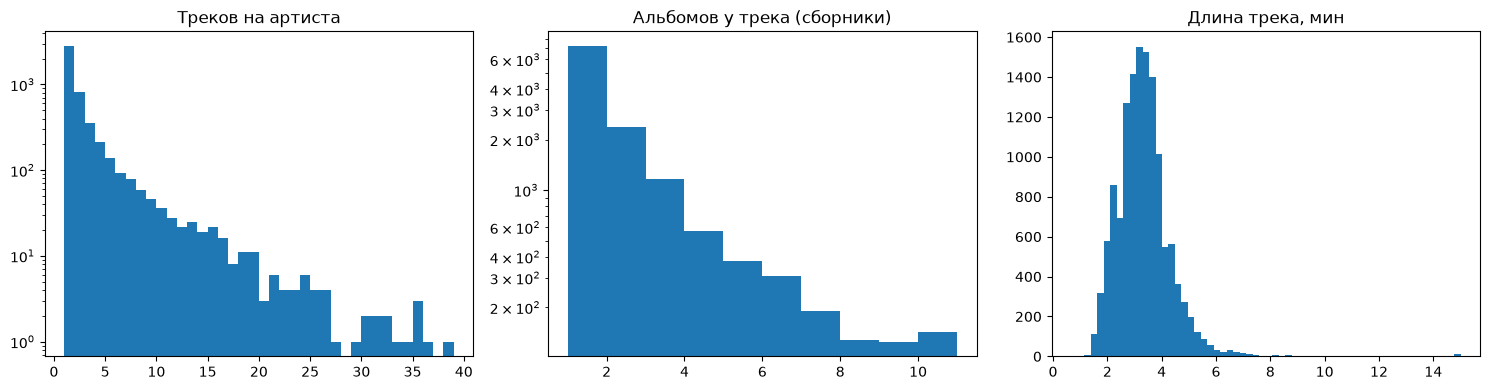

треков с артистом: 100.0%, артистов: 4,839; треков с альбомом: 100.0%, альбомов: 24,877
треков с несколькими артистами: 0, с несколькими альбомами: 5,953


In [ ]:
items = pl.DataFrame({"item_id": listens["item_id"].unique()})
art = data["artist_map"].join(items, on="item_id", how="semi")
alb = data["album_map"].join(items, on="item_id", how="semi")
track_len = listens.group_by("item_id").agg(pl.col("track_length_seconds").median())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
tpa = art.group_by("artist_id").len()["len"].to_numpy()
axes[0].hist(tpa, bins=np.arange(1, 40), log=True)
axes[0].set_title("Треков на артиста")
apt = alb.group_by("item_id").len()["len"].to_numpy()
axes[1].hist(apt, bins=np.arange(1, 12), log=True)
axes[1].set_title("Альбомов у трека (сборники)")
axes[2].hist(track_len["track_length_seconds"].clip(0, 900).to_numpy() / 60, bins=60)
axes[2].set_title("Длина трека, мин")
plt.tight_layout()
plt.show()

print(f"треков с артистом: {art['item_id'].n_unique() / items.height:.1%}, артистов: {art['artist_id'].n_unique():,}; "
      f"треков с альбомом: {alb['item_id'].n_unique() / items.height:.1%}, альбомов: {alb['album_id'].n_unique():,}")
print(f"треков с несколькими артистами: {(art.group_by('item_id').len()['len'] > 1).sum():,}, "
      f"с несколькими альбомами: {(apt > 1).sum():,}")

### 2.5. Активность во времени

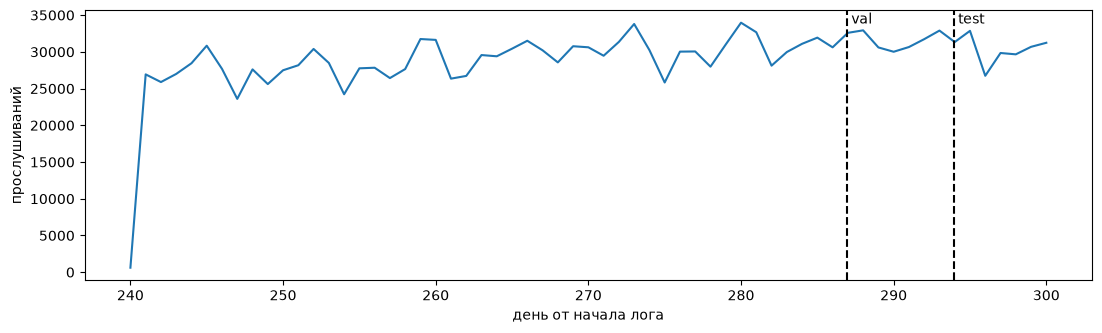

In [ ]:
daily = (
    listens.with_columns((pl.col("timestamp") // DAY).alias("day"))
    .group_by("day").agg(pl.len().alias("listens"), pl.col("uid").n_unique().alias("users")).sort("day")
)
t_max = meta["t_max"]
t_test, t_val = t_max - TEST_DAYS * DAY, t_max - (TEST_DAYS + VAL_DAYS) * DAY
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(daily["day"], daily["listens"])
for t, label in [(t_val, "val"), (t_test, "test")]:
    ax.axvline(t / DAY, color="k", ls="--")
    ax.text(t / DAY + 0.3, ax.get_ylim()[1] * 0.95, label)
ax.set_xlabel("день от начала лога")
ax.set_ylabel("прослушиваний")
plt.show()

Активность в подвыборке ровная, с недельной сезонностью и без провалов. Из-за недельной сезонности val и test взяты ровно по неделе:
так каждый период покрывает полный цикл.

**Итог по очистке и отбору.** Пропусков в данных нет, дубликаты удалены. Окно в 60 дней даёт свежие данные и около
6 недель на обучение. Четверть пользователей нужны, чтобы уложиться в лимиты, а k-core нужно, чтобы убрать треки, о которых коллаборативным моделям нечего выучить.

## 3. Протокол оценки

- **Разбиение по времени (глобальное):** `train` -- до `t_val`, `val` -- следующая неделя, `test` -- последняя неделя.
  Гиперпараметры подбираем, обучаясь на train и оценивая на val. Для финального сравнения переобучаемся на train + val
  с выбранными параметрами и оцениваем на test.
- **Кандидаты:** все треки обучающего каталога (полное ранжирование, без сэмплирования негативов).
- **Исключаем из выдачи** все треки, с которыми у пользователя было взаимодействие в обучающем периоде
  (прослушивание, лайк или дизлайк).
- **Пользователи для оценки:** есть в обучающем периоде и имеют ≥ 1 релевантный новый трек в периоде оценки.
  Холодных пользователей без истории не оцениваем.
- **Новые треки**, которых нет в обучающем каталоге, остаются. Порекомендовать их нельзя, поэтому
  они одинаково ограничивают метрики всех моделей.
- **Признаки и таргеты** моделей считаются только по обучающему периоду.

**Метрики при K = 10** :

- **NDCG@10 -- основная.** Учитывает порядок: в ленте пользователь слушает сверху вниз, ошибка на первой позиции дороже.
- **Recall@10** -- доля "хороших" треков, которые нашла модель. Нормируем на min(|rel|, 10): у активных
  пользователей бывают десятки релевантных треков за неделю, и без нормировки метрика для них ничего не говорит.
- **Coverage@10** (доля всего обучающего каталога в выдачах) и **mean_pop@10** (средняя доля пользователей, слушавших
  рекомендованный трек) в выборе моделей не участвуют. Они показывают, не вырождаются ли модели в предложение хитов.

In [ ]:
splits = make_splits(data, VAL_DAYS, TEST_DAYS)
rows = []
for name, s in splits.items():
    n_rel = np.array([len(s.ground_truth[u]) for u in s.eval_users])
    cold_items = sum(len(r - set(s.train.item_ids.tolist())) for r in s.ground_truth.values())
    active = data["listens"].filter((pl.col("timestamp") > s.t_fit) & (pl.col("timestamp") <= s.t_eval))["uid"].unique()
    rows.append({
        "сплит": name,
        "обучение: пользователи": s.train.n_users, "обучение: треки": s.train.n_items,
        "обучение: пары": s.train.pairs.height,
        "активных в периоде оценки": active.len(),
        "из них холодных": int((~active.is_in(pl.Series(s.train.user_ids).implode())).sum()),
        "оцениваемых пользователей": len(s.eval_users),
        "релевантных на пользователя (медиана)": float(np.median(n_rel)),
        "доля релевантных вне каталога": cold_items / n_rel.sum(),
    })
pd.DataFrame(rows).set_index("сплит").T

сплит,val,test
обучение: пользователи,2112.000000,2139.000000
обучение: треки,13030.000000,13122.000000
обучение: пары,598378.000000,670801.000000
активных в периоде оценки,1935.000000,1894.000000
из них холодных,26.000000,26.000000
оцениваемых пользователей,1718.000000,1664.000000
релевантных на пользователя (медиана),15.000000,14.500000
доля релевантных вне каталога,0.047828,0.021386


**Почему рекомендуем только новые треки.** Посмотрим, сколько релевантного на test приходится на уже знакомые треки
и сколько даёт тривиальное правило "верни пользователю 10 его самых дослушиваемых треков за последнюю неделю".

In [ ]:
from models.common import aggregate_pairs, is_relevant

s = splits["test"]
fit_pairs = aggregate_pairs(data, -1, s.t_fit)
rel_all = (
    aggregate_pairs(data, s.t_fit, s.t_eval).filter(is_relevant())
    .filter(pl.col("uid").is_in(pl.Series(s.train.user_ids).implode()))
    .join(fit_pairs.select("uid", "item_id", pl.lit(True).alias("known")), on=["uid", "item_id"], how="left")
    .with_columns(pl.col("known").fill_null(False))
)
gt_all = {u: set(i) for u, i in rel_all.group_by("uid").agg(pl.col("item_id")).iter_rows()}
own_top = dict(
    fit_pairs.filter(pl.col("last_ts") > s.t_fit - 7 * DAY)
    .sort(["uid", "n_full", "last_ts"], descending=[False, True, True])
    .group_by("uid", maintain_order=True).agg(pl.col("item_id").head(K)).iter_rows()
)
disc = 1 / np.log2(np.arange(2, K + 2))
ndcg_rep = np.mean([
    (np.array([it in rel for it in (own_top.get(u, []) + [None] * K)[:K]]) * disc).sum() / disc[:min(len(rel), K)].sum()
    for u, rel in gt_all.items()
])
print(f"доля уже знакомых треков среди релевантных пар test: {rel_all['known'].mean():.1%}")
print(f"NDCG@{K} правила «свои самые дослушиваемые за неделю» при разрешённых повторах: {ndcg_rep:.3f}")

доля уже знакомых треков среди релевантных пар test: 59.1%
NDCG@10 правила «свои самые дослушиваемые за неделю» при разрешённых повторах: 0.314


Больше половины релевантных пар на test приходится на повторы, и простое правило повторов даёт NDCG в несколько раз
выше, чем любая модель в постановке "только новые". Если разрешить повторы, метрика будет мерить в основном то,
насколько модель помнит пользователя, а не то, как она находит похожие треки. Поэтому модели сравниваются на поиске
новых треков.

## 4. Модели

У всех моделей одинаковый интерфейс: `fit(train)` принимает объект `Interactions`, `score(user_idx)` возвращает
оценки по всему каталогу. Top-10 с исключением известных треков и метрики считает общий код
(`models/common.py`, `models/metrics.py`).

### 4.0. Бейзлайн Popular

Неперсонализированный рейтинг: треки по числу слушателей за последние `days` дней обучения.
Единственный гиперпараметр `days` выбирает между всей историей и свежим окном. Popular служит нижней планкой
для остальных моделей.

In [ ]:
results = {}  # модель -> {params, val, test}
studies = {}  # модель -> таблица всех испытаний подбора


def tune_model(name, model_cls, space, n_trials, fixed=None):
    results[name], studies[name] = tune(model_cls, space, splits, n_trials, MAIN_METRIC, SEED, K, fixed, log_every=10)
    studies[name].to_csv(f"{OUT_DIR}/trials_{name}.csv", index=False)
    print(name, "best", results[name]["params"], "| val", round(results[name]["val"][MAIN_METRIC], 4),
          "| test", {k: round(v, 4) for k, v in results[name]["test"].items()})
    return studies[name].sort_values(MAIN_METRIC, ascending=False)


pop_grid = [{"days": d} for d in [None, 28, 14, 7, 3, 1]]
pop_val = pd.DataFrame([{**p, **run(Popular, p, splits["val"])} for p in pop_grid])
display(pop_val)
best = pop_grid[int(pop_val[MAIN_METRIC].idxmax())]
results["Popular"] = {"params": best, "val": pop_val.loc[pop_val[MAIN_METRIC].idxmax()].drop(list(best)).to_dict(),
                      "test": run(Popular, best, splits["test"], K)}
results["Popular"]

,days,ndcg@10,recall@10,coverage@10,mean_pop@10
0,NaN,0.026184,0.024731,0.007291,0.272966
1,28.0,0.026266,0.024305,0.006907,0.266631
2,14.0,0.028495,0.027191,0.006523,0.252460
3,7.0,0.030750,0.029885,0.006140,0.230379
4,3.0,0.032716,0.032443,0.006140,0.216765
5,1.0,0.030168,0.029456,0.005065,0.221951


{'params': {'days': 3},
 'val': {'ndcg@10': 0.03271641254920172,
  'recall@10': 0.03244313247223608,
  'coverage@10': 0.0061396776669224865,
  'mean_pop@10': 0.21676470339298248},
 'test': {'ndcg@10': 0.037403671572588434,
  'recall@10': 0.03886098710317461,
  'coverage@10': 0.0054107605547934765,
  'mean_pop@10': 0.1875443309545517}}

### 4.1. EASE

**Постановка.** Линейная item-item модель: оценка трека -- взвешенная сумма треков истории, $r_u = x_u B$.
Веса ищем как регрессию, восстанавливающую матрицу взаимодействий из самой себя, с запретом
предсказывать трек по нему же:

$$\min_B \|X - XB\|_F^2 + \lambda \|B\|_F^2 \quad \text{s.t.}\ \operatorname{diag}(B) = 0.$$

Решение в замкнутой форме: $P = (X^\top X + \lambda I)^{-1}$, $B_{ij} = -P_{ij} / P_{jj}$, $B_{jj} = 0$.
Обучение — одно обращение матрицы 13k × 13k.

**Пространство поиска:** $ \lambda \in [10, 10^4]$ по лог-шкале задаёт силу регуляризации, weighting $\in$ $\{$binary, full, log$\}$
определяет, что записывается в X: любое прослушивание, только дослушанные больше чем на 50% или
log(1 + число прослушиваний). 20 испытаний TPE.

In [ ]:
ease_space = lambda t: {"lam": t.suggest_float("lam", 10, 1e4, log=True),
                        "weighting": t.suggest_categorical("weighting", ["binary", "full", "log"])}
tune_model("EASE", EASE, ease_space, n_trials=20).head(10)

  испытание 10/20: ndcg@10 0.0684, лучшее 0.0694, 14 с


  испытание 20/20: ndcg@10 0.0667, лучшее 0.0698, 15 с


EASE best {'lam': 443.15301656437634, 'weighting': 'full'} | val 0.0698 | test {'ndcg@10': 0.0741, 'recall@10': 0.0733, 'coverage@10': 0.2023, 'mean_pop@10': 0.1158}


,number,lam,weighting,coverage@10,mean_pop@10,ndcg@10,recall@10,duration
12,12,443.153017,full,0.202302,0.111967,0.069751,0.070523,13.970581
13,13,311.867631,full,0.217805,0.108130,0.069628,0.070058,14.029520
18,18,267.590638,full,0.223408,0.106753,0.069501,0.069948,14.267490
11,11,570.387275,full,0.189946,0.115326,0.069488,0.070272,14.988073
6,6,233.458641,binary,0.238757,0.107528,0.069444,0.069580,14.384202
7,7,598.747491,full,0.187490,0.115959,0.069409,0.070117,13.557809
14,14,237.464615,full,0.227322,0.105670,0.069365,0.069850,14.400629
4,4,81.794995,binary,0.265311,0.102497,0.068664,0.069042,14.302480
5,5,684.792010,log,0.193553,0.120449,0.068587,0.069613,14.757413
0,0,132.929189,binary,0.254643,0.104587,0.068527,0.068459,15.306133


### 4.2. ItemKNN

**Постановка.** Item-based коллаборативная фильтрация. Сходство треков -- косинус столбцов X со штрафом
за малое число общих слушателей:

$$s_{ij} = \frac{x_i^\top x_j}{\|x_i\|\,\|x_j\| + \text{shrink}}.$$

У каждого трека оставляем `k` самых похожих, диагональ обнуляем. Оценка трека $j$ для пользователя --
сумма сходств с треками его истории: $r_{uj} = \sum_i x_{ui}\, s_{ij}$.

**Пространство поиска:** $k \in [2, 2000]$ (лог-шкала), shrink $\in [0, 500]$, weighting $\in \{$binary, full, log$\}$.
40 испытаний TPE.

In [ ]:
knn_space = lambda t: {"k": t.suggest_int("k", 2, 2000, log=True),
                       "shrink": t.suggest_float("shrink", 0, 500),
                       "weighting": t.suggest_categorical("weighting", ["binary", "full", "log"])}
tune_model("ItemKNN", ItemKNN, knn_space, n_trials=40).head(10)

  испытание 10/40: ndcg@10 0.0458, лучшее 0.0593, 3 с


  испытание 20/40: ndcg@10 0.0519, лучшее 0.0593, 4 с


  испытание 30/40: ndcg@10 0.0618, лучшее 0.0618, 3 с


  испытание 40/40: ndcg@10 0.0570, лучшее 0.0618, 3 с


ItemKNN best {'k': 9, 'shrink': 5.837278550557105, 'weighting': 'full'} | val 0.0618 | test {'ndcg@10': 0.0609, 'recall@10': 0.063, 'coverage@10': 0.2084, 'mean_pop@10': 0.09}


,number,k,shrink,weighting,coverage@10,mean_pop@10,ndcg@10,recall@10,duration
29,29,9,5.837279,full,0.214965,0.084101,0.061805,0.063918,2.644961
38,38,10,8.580616,log,0.196470,0.100007,0.060014,0.060917,3.495726
37,37,7,7.959234,log,0.211589,0.093746,0.059482,0.063253,3.377401
1,1,5,29.041806,binary,0.128856,0.128766,0.059331,0.060330,3.193483
33,33,5,1.131420,full,0.263315,0.067867,0.058997,0.063031,2.596931
30,30,5,34.726891,full,0.131773,0.113987,0.058877,0.059173,2.520601
22,22,5,33.164481,full,0.134305,0.112350,0.058533,0.058539,2.585735
36,36,5,32.733016,binary,0.123638,0.131930,0.058383,0.059423,3.290877
11,11,19,3.150967,binary,0.177744,0.115647,0.058377,0.059849,3.459443
14,14,13,46.512394,full,0.102149,0.136363,0.058149,0.058420,2.696158


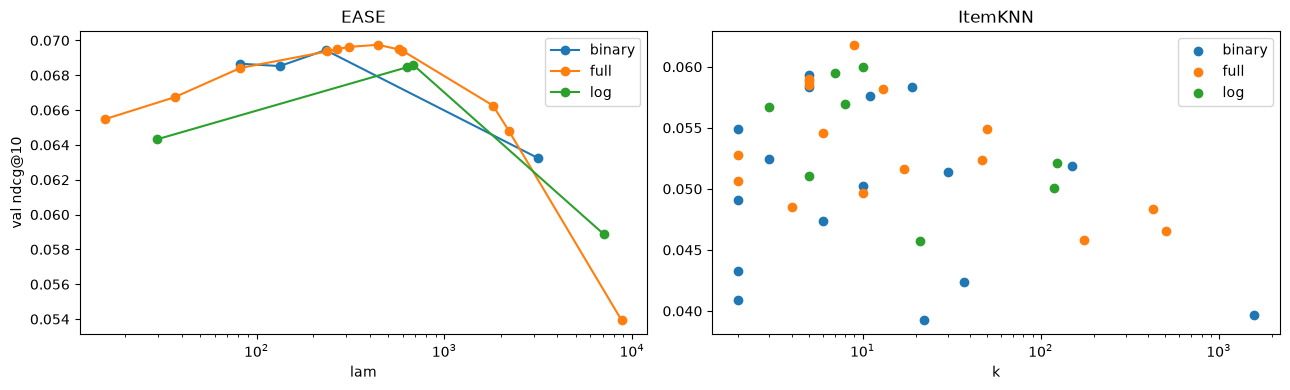

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for w, g in studies["EASE"].groupby("weighting"):
    g = g.sort_values("lam")
    axes[0].plot(g["lam"], g[MAIN_METRIC], "o-", label=w)
axes[0].set_xscale("log"); axes[0].set_xlabel("lam"); axes[0].set_ylabel(f"val {MAIN_METRIC}"); axes[0].set_title("EASE")
axes[0].legend()
for w, g in studies["ItemKNN"].groupby("weighting"):
    axes[1].scatter(g["k"], g[MAIN_METRIC], label=w)
axes[1].set_xscale("log"); axes[1].set_xlabel("k"); axes[1].set_title("ItemKNN")
axes[1].legend()
plt.tight_layout()
plt.show()

### 4.3. iALS

**Постановка**. Каждому пользователю $u$ и треку $i$ соответствует вектор длины factors: $x_u$ и $y_i$.
Оценка трека для пользователя — их скалярное произведение $x_u^\top y_i$. Для каждой пары задаём предпочтение $p_{ui}$ и уверенность $c_{ui}$;
у ненаблюдённых пар $p = 0$, $c = 1$:

$$\min_{X, Y} \sum_{u, i} c_{ui} (p_{ui} - x_u^\top y_i)^2 + \lambda \Big(\sum_u \|x_u\|^2 + \sum_i \|y_i\|^2\Big).$$

Базовая версия: $p_{ui} = 1$ для наблюдённых пар, $c_{ui} = 1 + \alpha \log(1 + n_{ui})$, где $n_{ui}$ — число
прослушиваний (или дослушиваний при `weighting=full`). Обучение — попеременные точные МНК-шаги:

$$x_u = \big(Y^\top Y + Y^\top (C_u - I) Y + \lambda I\big)^{-1} Y^\top C_u p_u,$$

$Y^\top Y$ общий для всех пользователей, поправка считается только по наблюдённым трекам; для треков симметрично.
Оценка — $x_u^\top y_i$.

**Пространство поиска:** factors $\in \{32, 64, 128, 256\}$, reg $\in [0.1, 1000]$ (лог), $\alpha \in [0.5, 100]$ (лог),
iters $ \in [5, 20]$, weighting $\in \{$binary, full$\}$. 40 испытаний TPE.

- factors — длина векторов $x_u$ и $y_i$. Длинные векторы различают более тонкие оттенки вкуса, но учатся дольше
  и легче переобучаются.
- reg — сила регуляризации $\lambda$, штраф за большие значения в векторах. Не даёт модели подгоняться под случайные
  взаимодействия; слишком большой reg сводит рекомендации к популярному.
- $\alpha$ — насколько сильнее модель доверяет частым взаимодействиям, чем однократным.
- iters — число итераций ALS: сколько раз поочерёдно пересчитываются векторы пользователей и треков.

In [ ]:
ials_space = lambda t: {"factors": t.suggest_categorical("factors", [32, 64, 128, 256]),
                        "reg": t.suggest_float("reg", 0.1, 1000, log=True),
                        "alpha": t.suggest_float("alpha", 0.5, 100, log=True),
                        "iters": t.suggest_int("iters", 5, 20),
                        "weighting": t.suggest_categorical("weighting", ["binary", "full"])}
tune_model("iALS", IALS, ials_space, n_trials=40, fixed={"seed": SEED}).head(10)

  испытание 10/40: ndcg@10 0.0580, лучшее 0.0691, 7 с


  испытание 20/40: ndcg@10 0.0692, лучшее 0.0692, 9 с


  испытание 30/40: ndcg@10 0.0695, лучшее 0.0697, 10 с


  испытание 40/40: ndcg@10 0.0690, лучшее 0.0698, 12 с


iALS best {'factors': 64, 'reg': 0.17357478982853064, 'alpha': 2.472562346406127, 'iters': 17, 'weighting': 'full'} | val 0.0698 | test {'ndcg@10': 0.0699, 'recall@10': 0.0708, 'coverage@10': 0.2284, 'mean_pop@10': 0.1017}


,number,alpha,factors,iters,reg,weighting,coverage@10,mean_pop@10,ndcg@10,recall@10,duration
36,36,2.472562,64,17,0.173575,full,0.221566,0.098835,0.069796,0.069937,10.936022
24,24,2.774716,64,16,2.850832,full,0.221796,0.099018,0.069668,0.070051,10.368047
31,31,2.472548,64,16,3.419904,full,0.216731,0.099872,0.069643,0.069686,10.191132
28,28,2.562810,64,18,1.530397,full,0.220721,0.099113,0.069608,0.069627,11.370471
29,29,2.772505,64,16,1.686712,full,0.223868,0.098560,0.069492,0.070114,10.189559
21,21,1.472354,64,12,0.117653,full,0.204605,0.101896,0.069219,0.070879,7.952634
19,19,1.503206,64,13,0.133043,full,0.205679,0.101728,0.069150,0.070698,8.530331
10,10,6.139180,64,17,60.879519,full,0.194474,0.108905,0.069089,0.070007,10.892165
6,6,2.802624,64,11,0.151673,full,0.226554,0.098528,0.069072,0.071455,7.663916
34,34,1.570835,64,13,9.372108,full,0.193553,0.105119,0.069047,0.070418,8.538294


### 4.4. iALS с собственным целевым сигналом

**Идея.** Базовый iALS считает любое наблюдённое взаимодействие предпочтением $p = 1$ и меняет только уверенность.
Для музыки это плохо подходит. По EDA прослушивания почти бинарны: трек либо пропускают в первые секунды, либо
дослушивают, и EASE, ItemKNN и iALS лучше учатся только на дослушанных. Пропуск скорее значит "не нравится",
дизлайк -- явный негатив, лайк -- сильный позитив. Popular показал, что свежие события важнее старых, то есть вкус
дрейфует. Поэтому меняется сам целевой сигнал: вместо бинарного он становится градуированным, учитывает
явные негативы и выцветает со временем.

По каждой паре обучающего периода считаем свидетельства "за" и "против":

$$e^+_{ui} = n^{full}_{ui} + \beta \cdot \text{liked}_{ui}, \qquad
e^-_{ui} = \gamma \cdot (n_{ui} - n^{full}_{ui}) + D \cdot \text{disliked}_{ui}.$$

Целевой сигнал равен доле свидетельств "за", умноженной на затухание интереса с давностью. Уверенность устроена
так же, как у базового iALS, но считается от объёма свидетельств:

$$p_{ui} = \frac{e^+_{ui}}{e^+_{ui} + e^-_{ui}} \cdot 2^{-\Delta t_{ui} / h} \in [0, 1], \qquad
c_{ui} = 1 + \alpha \log(1 + e^+_{ui} + e^-_{ui}),$$

$\Delta t_{ui}$ -- дни от последнего события пары до конца обучения, $h$ -- период полураспада интереса.
Трек, который пользователь дослушивал вчера, получает $p \approx 1$; дослушивал два месяца назад --
$p \approx 2^{-60/h}$; только пропускал или дизлайкнул -- $p \approx 0$ с уверенностью выше, чем у ненаблюдённой пары.
Обучение идёт тем же ALS (`models/ials.py`), меняется только то, что модель приближает.

Затухание стоит в таргете, а не в уверенности. Вес уверенности говорит о том, насколько мы доверяем наблюдению,
а не о том, насколько трек нужен пользователю сейчас. Старое дослушивание надёжно говорит о прошлом вкусе и слабо
о текущем, а это свойство самого предпочтения. Ablation ниже сравнивает оба варианта.

**Пространство поиска:** параметры iALS как выше, кроме `weighting` (его заменяет сигнал), плюс
$\beta \in [0, 5]$ (вес лайка в дослушиваниях), $\gamma \in [0, 2]$ (вес пропуска), half_life (h) $\in [2, 120]$ дней (лог),
dislike_weight (D) $\in [0, 10]$. Бюджет, сплиты и метрика те же, что у базового iALS: 40 испытаний TPE.

In [ ]:
custom_space = lambda t: {"factors": t.suggest_categorical("factors", [32, 64, 128, 256]),
                          "reg": t.suggest_float("reg", 0.1, 1000, log=True),
                          "alpha": t.suggest_float("alpha", 0.5, 100, log=True),
                          "iters": t.suggest_int("iters", 5, 20),
                          "beta": t.suggest_float("beta", 0, 5),
                          "gamma": t.suggest_float("gamma", 0, 2),
                          "half_life": t.suggest_float("half_life", 2, 120, log=True),
                          "dislike_weight": t.suggest_float("dislike_weight", 0, 10)}
tune_model("iALS custom", IALSCustom, custom_space, n_trials=40, fixed={"seed": SEED}).head(10)

  испытание 10/40: ndcg@10 0.0265, лучшее 0.0778, 12 с


  испытание 20/40: ndcg@10 0.0750, лучшее 0.0778, 36 с


  испытание 30/40: ndcg@10 0.0713, лучшее 0.0778, 20 с


  испытание 40/40: ndcg@10 0.0770, лучшее 0.0782, 32 с


iALS custom best {'factors': 256, 'reg': 25.05351654139428, 'alpha': 1.743637953546973, 'iters': 7, 'beta': 2.6738703245170514, 'gamma': 0.2718705446684017, 'half_life': 28.996630003773102, 'dislike_weight': 8.647219530424454} | val 0.0782 | test {'ndcg@10': 0.0832, 'recall@10': 0.0832, 'coverage@10': 0.1968, 'mean_pop@10': 0.1066}


,number,alpha,beta,dislike_weight,factors,gamma,half_life,iters,reg,coverage@10,mean_pop@10,ndcg@10,recall@10,duration
35,35,1.743638,2.673870,8.647220,256,0.271871,28.996630,7,25.053517,0.190330,0.104192,0.078231,0.078926,28.219043
7,7,2.886531,1.554912,6.375575,256,0.650367,39.662504,6,31.130960,0.211512,0.098614,0.077796,0.079703,24.524225
36,36,2.926834,1.049847,8.965071,256,0.914889,18.886386,5,17.734605,0.249578,0.088431,0.077426,0.078358,20.459324
39,39,1.657830,1.618964,6.260388,256,0.075567,28.011709,8,23.400223,0.198388,0.102917,0.076975,0.077808,31.855663
32,32,1.324061,1.499315,5.852041,256,0.386158,44.509712,8,22.185771,0.199616,0.102329,0.076712,0.077825,31.781204
34,34,2.346218,0.442062,9.864970,256,0.388490,37.938093,7,26.023986,0.220031,0.097563,0.076675,0.078160,28.334084
37,37,4.760335,0.604776,8.758866,256,0.916877,39.188317,6,31.432801,0.252341,0.090391,0.076533,0.079235,24.223993
0,0,1.142663,4.330881,0.205845,64,1.202230,36.315342,5,0.420799,0.194705,0.101200,0.076221,0.075936,4.230211
22,22,2.203872,1.115195,7.699797,256,0.636328,16.019312,6,33.178097,0.134766,0.118724,0.075947,0.075423,24.333499
30,30,1.550343,2.469701,0.685991,64,1.259976,32.695077,6,5.484719,0.192556,0.101393,0.075590,0.074942,4.829198


**Ablation своего сигнала.** С лучшими параметрами по очереди выключаем компоненты сигнала. Обучение на train + val,
оценка на test, для сравнения рядом базовый iALS с его лучшими параметрами:

In [ ]:
best_custom = {**results["iALS custom"]["params"], "seed": SEED}
variants = {
    "iALS (база, лучшие параметры)": (IALS, {**results["iALS"]["params"], "seed": SEED}),
    "iALS custom (полный сигнал)": (IALSCustom, best_custom),
    "без негативов (gamma = 0, D = 0)": (IALSCustom, {**best_custom, "gamma": 0.0, "dislike_weight": 0.0}),
    "без лайков (beta = 0)": (IALSCustom, {**best_custom, "beta": 0.0}),
    "без затухания (h = ∞)": (IALSCustom, {**best_custom, "half_life": 1e9}),
    "затухание в уверенности, а не в таргете": (IALSCustom, {**best_custom, "decay_in": "confidence"}),
}
ablation = pd.DataFrame({name: run(cls, p, splits["test"], K) for name, (cls, p) in variants.items()}).T
ablation

,ndcg@10,recall@10,coverage@10,mean_pop@10
"iALS (база, лучшие параметры)",0.069917,0.070845,0.228395,0.101749
iALS custom (полный сигнал),0.083224,0.083203,0.196769,0.106570
"без негативов (gamma = 0, D = 0)",0.082614,0.081419,0.201875,0.107970
без лайков (beta = 0),0.082196,0.082154,0.194864,0.107653
без затухания (h = ∞),0.076237,0.077471,0.243179,0.097961
"затухание в уверенности, а не в таргете",0.078580,0.079299,0.221232,0.103316


### 4.5. Факторизационная машина с метапризнаками

**Постановка**. Пара (пользователь, трек) -- разреженный вектор признаков $z$:

$$\hat y(z) = w_0 + \sum_f w_f z_f + \sum_{f < g} \langle v_f, v_g \rangle z_f z_g
= w_0 + \sum_f w_f z_f + \tfrac12 \sum_k \Big[\big(\textstyle\sum_f v_{fk} z_f\big)^2 - \sum_f v_{fk}^2 z_f^2\Big].$$

Слагаемые, зависящие только от пользователя, не влияют на ранжирование, поэтому оценку трека можно считать как
$s(u, i) = \sum_{g \in i} w_g z_g + \langle \sum_{f \in u} v_f z_f, \sum_{g \in i} v_g z_g \rangle + (\text{попарные взаимодействия признаков трека})$,
и весь каталог оценивается одним матричным умножением. Обучение -- BPR: $-\log \sigma(s(u, i) - s(u, j))$ по
положительной паре и `n_neg` случайным трекам $j$, плюс L2 на векторы, Adam.

**Признаки.** Используется только то, что известно в момент рекомендации: статичные свойства трека и статистики обучающего периода.

| сторона | признак | зачем |
|---|---|---|
| пользователь | id | персональный вектор |
| пользователь | активность (число треков, бакет) | активные слушают более нишевое |
| пользователь | доля органических прослушиваний | сам включает треки или слушает ленту рекомендаций |
| пользователь | доля дослушанных треков | насколько придирчив |
| трек | id | индивидуальный вектор |
| трек | артист | вкус переносится между треками артиста, помогает редким трекам |
| трек | альбомы (multi-hot, ≤ 4 крупнейших) | треки одного альбома похожи; у сборников альбомов до 241 |
| трек | длина (бакет) | короткие интро / длинные миксы слушают иначе |
| трек | популярность за обучение и за последнюю неделю (бакеты) | общая и свежая популярность |

**Бакеты.** FM работает с категориальными признаками: у каждого значения свой вектор $v_f$. Поэтому числовые признаки
разбиты на квантильные бакеты -- группы с равным числом объектов, и каждый бакет становится отдельным
категориальным признаком. Так модель может по-разному обращаться, например, с короткими и длинными треками,
а не только линейно по длине. Число бакетов: длина трека -- 8, активность пользователя (по логарифму числа треков) -- 8,
доля органики -- 5, доля дослушанных -- 5, популярность за обучение -- 10, за последнюю неделю -- 5.

**Альбомы.** Трек может входить в несколько альбомов: оригинальный альбом, сингл, сборники. В признаках стоит вес
$1/n$ у каждого из $n$ альбомов трека (multi-hot). Берём не больше 4 альбомов -- тех, где больше всего треков
каталога: у популярных треков бывает до 241 сборника, это замедляет обучение, а альбом с одним треком каталога
ни с чем его не связывает.

`meta` = content включает только статичные признаки трека (артист, альбомы, длина), all -- все признаки.
Вариант с одними id проверяется в ablation ниже и в подборе не участвует: по заданию FM должна использовать метапризнаки.

**Пространство поиска:** meta $\in \{$content, all$\}$, dim $\in \{32, 64, 128\}$, lr $\in [3 \cdot 10^{-4}, 10^{-2}]$ (лог),
reg $\in [10^{-4}, 3 \cdot 10^{-2}]$ (лог), epochs $\in [5, 40]$, n_neg $\in \{1, 4, 8\}$. 40 испытаний TPE.

- meta -- набор признаков: content или all.
- dim -- длина векторов $v_f$ у всех признаков.
- lr -- шаг обучения Adam.
- reg -- сила L2-регуляризации векторов.
- epochs -- сколько раз модель проходит по всем положительным парам.
- n_neg -- сколько случайных треков $j$ берётся на каждую положительную пару

In [ ]:
item_meta = item_metadata(data)
fm_space = lambda t: {"meta": t.suggest_categorical("meta", ["content", "all"]),
                      "dim": t.suggest_categorical("dim", [32, 64, 128]),
                      "lr": t.suggest_float("lr", 3e-4, 1e-2, log=True),
                      "reg": t.suggest_float("reg", 1e-4, 3e-2, log=True),
                      "epochs": t.suggest_int("epochs", 5, 40),
                      "n_neg": t.suggest_categorical("n_neg", [1, 4, 8])}

tune_model("FM", FM, fm_space, n_trials=40, fixed={"item_meta": item_meta, "seed": SEED}).head(10)

  испытание 10/40: ndcg@10 0.0429, лучшее 0.0624, 12 с


  испытание 20/40: ndcg@10 0.0595, лучшее 0.0657, 300 с


  испытание 30/40: ndcg@10 0.0574, лучшее 0.0657, 78 с


  испытание 40/40: ndcg@10 0.0635, лучшее 0.0657, 269 с


FM best {'meta': 'content', 'dim': 128, 'lr': 0.000564560478495367, 'reg': 0.003829077345810721, 'epochs': 35, 'n_neg': 8} | val 0.0657 | test {'ndcg@10': 0.066, 'recall@10': 0.0667, 'coverage@10': 0.2491, 'mean_pop@10': 0.0926}


,number,dim,epochs,lr,meta,n_neg,reg,coverage@10,mean_pop@10,ndcg@10,recall@10,duration
14,14,128,35,0.000565,content,8,0.003829,0.240599,0.090357,0.065667,0.068964,264.966662
24,24,128,30,0.001640,content,8,0.007907,0.224405,0.090944,0.064637,0.065369,229.995170
21,21,128,27,0.001809,content,8,0.001921,0.307137,0.075127,0.064450,0.066024,207.277641
16,16,128,15,0.001612,content,8,0.001520,0.275595,0.080332,0.064236,0.066533,114.765791
11,11,128,27,0.000930,content,8,0.000212,0.317652,0.077708,0.063774,0.065572,204.840850
28,28,128,36,0.000732,content,8,0.003797,0.267997,0.086040,0.063580,0.066337,275.384621
39,39,128,35,0.002983,content,8,0.007715,0.227398,0.088513,0.063548,0.064445,268.790276
31,31,128,14,0.001683,content,8,0.000514,0.283883,0.079235,0.063499,0.066715,108.365276
22,22,128,26,0.001532,content,8,0.002558,0.290407,0.077990,0.062734,0.064434,200.419156
5,5,128,34,0.001172,content,8,0.000470,0.341750,0.073862,0.062380,0.064494,254.797206


**Влияние метапризнаков.** Лучшие параметры FM с разными наборами признаков, обучение на train + val, оценка на test:

In [ ]:
fm_best = {**results["FM"]["params"], "item_meta": item_meta, "seed": SEED}
fm_ablation = pd.DataFrame({
    f"meta={m}": run(FM, {**fm_best, "meta": m}, splits["test"], K) for m in ["none", "content", "all"]
}).T
fm_ablation

,ndcg@10,recall@10,coverage@10,mean_pop@10
meta=none,0.065347,0.064775,0.285170,0.089896
meta=content,0.065988,0.066703,0.249124,0.092572
meta=all,0.064656,0.064735,0.281207,0.096815


## 5. Сравнение

Параметры каждой модели выбраны на val, метрики на test посчитаны после переобучения на train + val.

In [ ]:
def results_table(results):
    rows = []
    for name, r in results.items():
        rows.append({"модель": name, "параметры": r["params"],
                     **{f"val {k}": v for k, v in r["val"].items() if k == MAIN_METRIC},
                     **{f"test {k}": v for k, v in r["test"].items()}})
    return pd.DataFrame(rows).set_index("модель")


import json

table = results_table(results)
print(table.to_string())
with open(f"{OUT_DIR}/results.json", "w") as f:
    json.dump(results, f, indent=2, default=str)
table

                                                                                                                                                                                                                     параметры  val ndcg@10  test ndcg@10  test recall@10  test coverage@10  test mean_pop@10
модель                                                                                                                                                                                                                                                                                                       
Popular                                                                                                                                                                                                            {'days': 3}     0.032716      0.037404        0.038861          0.005411          0.187544
EASE                                                                                          

,параметры,val ndcg@10,test ndcg@10,test recall@10,test coverage@10,test mean_pop@10
модель,,,,,,
Popular,{'days': 3},0.032716,0.037404,0.038861,0.005411,0.187544
EASE,"{'lam': 443.15301656437634, 'weighting': 'full'}",0.069751,0.074090,0.073262,0.202256,0.115830
ItemKNN,"{'k': 9, 'shrink': 5.837278550557105, 'weighti...",0.061805,0.060935,0.062989,0.208429,0.090022
iALS,"{'factors': 64, 'reg': 0.17357478982853064, 'a...",0.069796,0.069917,0.070845,0.228395,0.101749
iALS custom,"{'factors': 256, 'reg': 25.05351654139428, 'al...",0.078231,0.083224,0.083203,0.196769,0.106570
FM,"{'meta': 'content', 'dim': 128, 'lr': 0.000564...",0.065667,0.065988,0.066703,0.249124,0.092572


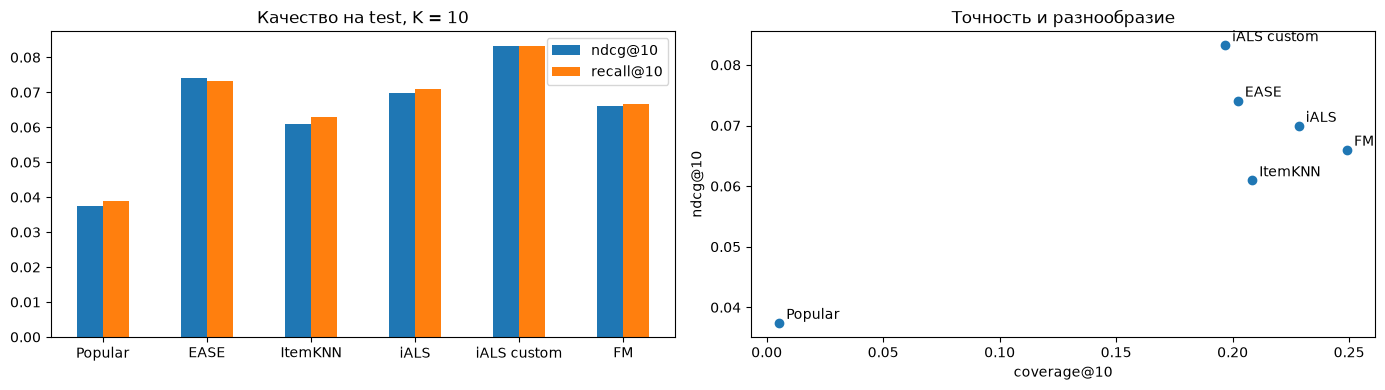

In [ ]:
test = pd.DataFrame({name: r["test"] for name, r in results.items()}).T
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
test[[f"ndcg@{K}", f"recall@{K}"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title(f"Качество на test, K = {K}")
axes[1].scatter(test[f"coverage@{K}"], test[f"ndcg@{K}"])
for name, row in test.iterrows():
    axes[1].annotate(name, (row[f"coverage@{K}"], row[f"ndcg@{K}"]), textcoords="offset points", xytext=(5, 3))
axes[1].set_xlabel(f"coverage@{K}")
axes[1].set_ylabel(f"ndcg@{K}")
axes[1].set_title("Точность и разнообразие")
plt.tight_layout()
plt.show()

## 6. Выводы

**Итог на test.** Главная метрика -- NDCG@10. Лучший метод -- iALS со своим целевым сигналом:
NDCG@10 = 0.0832, Recall@10 = 0.0832. Это на 19% выше базового iALS (0.0699) и на 12% выше EASE (0.0741). За ними идут FM (0.0660) и ItemKNN (0.0609), Popular (0.0374) показывает самый низкий результат.
На val модели выстраиваются в том же порядке, только EASE и iALS там равны (0.0698), а на test EASE впереди.

**Лучшие настройки.**
- EASE, ItemKNN и iALS при подборе выбрали `weighting = full`: взаимодействием считается только трек, дослушанный
  больше чем наполовину. Пропущенные треки оказались шумом, а не сигналом интереса.
- ItemKNN лучше всего работает с очень узкой окрестностью (k = 9 соседей), EASE — с умеренной регуляризацией (λ ≈ 440).
- Popular лучше считать по последним 3 дням: популярность в музыке быстро меняется.

**Свой целевой сигнал.** Больше всего дало затухание интереса с давностью внутри таргета: без него NDCG падает
до 0.0762, на 0.0070. В весе уверенности то же затухание работает хуже (0.0786). Давнее дослушивание надёжно говорит
о прошлом вкусе и слабо о нынешнем, поэтому выцветать должно само предпочтение. Даже без затухания градуированный
сигнал (доля дослушиваний и лайков) обходит базовый iALS: 0.0762 против 0.0699. Лайки и отрицательная обратная связь
добавляют по 0.0006–0.0010, это уровень шума. Дизлайков мало (0.4% пар), а рекомендуются только новые треки,
так что отрицательная оценка уже прослушанного трека влияет на выдачу лишь косвенно.

**Метапризнаки в FM.** На тёплых пользователях и треках они почти не помогают. С лучшими параметрами на test
только id дают 0.0653, id с артистом, альбомами и длиной — 0.0660, все признаки — 0.0647. Признаки пользователя и популярности трека скорее мешают: в подборе
лучший результат с ними 0.0517, без них 0.0657 (подбор выбрал content в 34 испытаниях из 40). Зато у FM самая
широкая выдача (coverage 25% против 20–23%) и почти самые непопулярные треки (mean_pop 0.093, у ItemKNN 0.090). Сильнее метапризнаки должны помогать холодным трекам, но в этой постановке кандидаты
берутся только из обучающего каталога.

**Точность и разнообразие.** Персонализированные модели показывают за неделю 20–25% каталога и рекомендуют треки
заметно менее популярные, чем Popular (mean_pop 0.09–0.12 против 0.19). Самая точная модель не самая разнообразная:
coverage у iALS со своим сигналом 19.7%, у FM 24.9%. Это может быть важно, например, когда сервис хочет привлекать новых артистов. Если я нишевый артист, и у меня очень мало слушателей, вероятность мне стрельнуть в каких-нибудь рекомендациях сервиса с высоким coverage выше, чем в рекомендациях сервиса с низким coverage. Соответственно, мне выгоднее выбирать и целиться в развитие на площадке, которая может мне предоставить рост. Поэтому хоть целевой метрикой в текущей задаче и является NDCG@10, coverage также может быть важен (в другой постановке задачи).

**Ограничения.**
- Одна подвыборка (60 дней, 25% пользователей) и одна тестовая неделя, доверительных интервалов нет.
- Рекомендуются только новые треки. 59% релевантных пар test -- повторы уже слышанного, и правило «свой top-10
  по прослушиваниям» дало бы на всех релевантных парах NDCG 0.31. Задача с повторами по сути другая.
- k-core считался по всему окну, включая val и test. Это небольшое смещение отбора в пользу активных пользователей
  и популярных треков.
- ID в Yambda анонимны, поэтому рекомендации нельзя проверить глазами.